# Bulk RNA-seq part 1: from sequencing reads to a count matrix

**Case study: Can the transcription factors FOXA1 and HNF4A activate liver genes in a blood cell line?**

Hansen JL, Loell KJ, Cohen BA. *A test of the pioneer factor hypothesis using ectopic liver gene activation.* eLife (2022) 11:e73358. https://elifesciences.org/articles/73358

**Background**

Cell identity is controlled by transcription factors (TFs). In the nucleus, DNA is packed into chromatin, which can be more or less accessible. The **pioneer factor hypothesis** states that a special class of TFs, called *pioneer factors*, can bind to closed chromatin, open it up and then recruit *non-pioneer factors*, which according to this hypothesis depend on the pioneer factor to bind and activate gene expression.

In the liver, FOXA1 is the textbook example of a pioneer factor and HNF4A is considered a non-pioneer factor. In this paper the authors tested the pioneer factor hypothesis by expressing FOXA1, HNF4A, or both, in K562 cells. K562 is a leukemia cell line (blood), so liver genes are normally silent in these cells.

The authors made three K562 cell lines in which expression of the human *FOXA1* and/or *HNF4A* gene can be switched on by adding doxycycline (dox) to the medium (a so-called Tet-On system, using the pINDUCER21 vector):

- FOXA1 line: dox induces FOXA1
- HNF4A line: dox induces HNF4A
- FOXA1-HNF4A line: dox induces both FOXA1 and HNF4A

For each line, RNA was sequenced from cells without dox (uninduced) and with 0.5 µg/ml dox for 24 hours (induced), in triplicate. This gives 3 x 2 x 3 = 18 samples.

**Research questions:**

1. Which genes are activated upon expression of FOXA1, HNF4A or both?
2. Are these genes liver (or intestine) specific?
3. Do FOXA1 and HNF4A activate the same genes or different genes?

In this notebook we go from raw sequencing reads to a count matrix. In the second notebook we use this count matrix to perform differential expression analysis and to interpret the results.

**Note**:

All software (sra-tools, FastQC, MultiQC, STAR, samtools, subread) can be installed in a single mamba environment. This environment also contains `bash_kernel`, which allows us to run bash commands in a Jupyter notebook.

    mamba create -n rnaseq_tools -c conda-forge -c bioconda sra-tools fastqc multiqc star samtools subread bash_kernel pigz

To use this environment in Jupyter we have to register it as a *kernel*. Run the following commands in a terminal (not in this notebook):

```
mamba activate rnaseq_tools
KERNEL_DIR=$(jupyter --data-dir)/kernels/bash-foxa1_hnf4a
mkdir -p ${KERNEL_DIR}
cat > ${KERNEL_DIR}/kernel.json << EOF
{
  "argv": ["${CONDA_PREFIX}/bin/python", "-m", "bash_kernel", "-f", "{connection_file}"],
  "display_name": "Bash (FoxA1/Hnf4a RNA-seq)",
  "language": "bash",
  "env": {"PATH": "${CONDA_PREFIX}/bin:/usr/local/bin:/usr/bin:/bin", "PS1": "$"}
}
EOF
jupyter kernelspec list   # the kernel bash-foxa1_hnf4a should be listed
```

The file `kernel.json` tells Jupyter how to start the kernel: using the python of the `rnaseq_tools` environment (`${CONDA_PREFIX}` is the location of the active environment). We also add the `bin` folder of the environment to the `PATH`, so the tools (STAR, samtools, ...) are found, even when Jupyter itself is started from another environment.

Next, (re)start Jupyter and select the kernel "Bash (FoxA1/Hnf4a RNA-seq)" (Kernel > Change Kernel).

Some steps (downloading all reads, building the genome index, aligning all reads) take a long time (up to several hours). For these steps the expected run time is mentioned.

## Step 0: set up working directory

All data will be stored in the folder `data`, next to this notebook.

In [1]:
mkdir -p data
cd data

We will store the location of the reference genome (and the STAR index, see Step 3) in a variable, so we only have to change it in one place. Here the genome is stored in the folder `data/genome`. If you store it somewhere else (e.g. to share it between projects), change this path.

In [2]:
GENOME_DIR=genome
ls ${GENOME_DIR}

GRCh38.gencode_v46.star_d


GRCh38.primary_assembly.genome.fa


GRCh38.primary_assembly.genome.fa.fai


GRCh38.primary_assembly.genome.fa.gz


gencode.v46.primary_assembly.annotation.gtf


gencode.v46.primary_assembly.annotation.gtf.gz


## Step 1: get reads

The data is deposited in the Gene Expression Omnibus (GEO) under accession number GSE182190:

https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE182190

This GEO series contains RNA-seq, ATAC-seq and CUT&Tag data. We will only use the **RNA-seq** samples (GSM5520289 - GSM5520306).

On the GEO page, click on "SRA Run Selector" at the bottom of the page. This will show you a table with all sequencing runs (SRR numbers) belonging to this GEO series together with their metadata.

The information we need for the RNA-seq samples is summarized in the table below:

| GEO sample | SRA run | Cell line | Treatment | Replicate | Our sample name |
|---|---|---|---|---|---|
| GSM5520289 | SRR15477578 | FOXA1 | uninduced | 1 | FOXA1_U1 |
| GSM5520290 | SRR15477580 | FOXA1 | uninduced | 2 | FOXA1_U2 |
| GSM5520291 | SRR15477582 | FOXA1 | uninduced | 3 | FOXA1_U3 |
| GSM5520292 | SRR15477584 | FOXA1 | induced | 1 | FOXA1_I1 |
| GSM5520293 | SRR15477586 | FOXA1 | induced | 2 | FOXA1_I2 |
| GSM5520294 | SRR15477588 | FOXA1 | induced | 3 | FOXA1_I3 |
| GSM5520295 | SRR15477590 | HNF4A | uninduced | 1 | HNF4A_U1 |
| GSM5520296 | SRR15477592 | HNF4A | uninduced | 2 | HNF4A_U2 |
| GSM5520297 | SRR15477594 | HNF4A | uninduced | 3 | HNF4A_U3 |
| GSM5520298 | SRR15477596 | HNF4A | induced | 1 | HNF4A_I1 |
| GSM5520299 | SRR15477598 | HNF4A | induced | 2 | HNF4A_I2 |
| GSM5520300 | SRR15477600 | HNF4A | induced | 3 | HNF4A_I3 |
| GSM5520301 | SRR15477602 | FOXA1-HNF4A | uninduced | 1 | FOXA1HNF4A_U1 |
| GSM5520302 | SRR15477604 | FOXA1-HNF4A | uninduced | 2 | FOXA1HNF4A_U2 |
| GSM5520303 | SRR15477606 | FOXA1-HNF4A | uninduced | 3 | FOXA1HNF4A_U3 |
| GSM5520304 | SRR15477608 | FOXA1-HNF4A | induced | 1 | FOXA1HNF4A_I1 |
| GSM5520305 | SRR15477611 | FOXA1-HNF4A | induced | 2 | FOXA1HNF4A_I2 |
| GSM5520306 | SRR15477613 | FOXA1-HNF4A | induced | 3 | FOXA1HNF4A_I3 |

We will save this table as a tab separated file, we will use it later to rename the files.

In [3]:
cat > samples.tsv << EOF
SRR15477578	FOXA1_U1
SRR15477580	FOXA1_U2
SRR15477582	FOXA1_U3
SRR15477584	FOXA1_I1
SRR15477586	FOXA1_I2
SRR15477588	FOXA1_I3
SRR15477590	HNF4A_U1
SRR15477592	HNF4A_U2
SRR15477594	HNF4A_U3
SRR15477596	HNF4A_I1
SRR15477598	HNF4A_I2
SRR15477600	HNF4A_I3
SRR15477602	FOXA1HNF4A_U1
SRR15477604	FOXA1HNF4A_U2
SRR15477606	FOXA1HNF4A_U3
SRR15477608	FOXA1HNF4A_I1
SRR15477611	FOXA1HNF4A_I2
SRR15477613	FOXA1HNF4A_I3
EOF
cat samples.tsv

SRR15477578FOXA1_U1


SRR15477580FOXA1_U2


SRR15477582FOXA1_U3


SRR15477584FOXA1_I1


SRR15477586FOXA1_I2


...

SRR15477604FOXA1HNF4A_U2


SRR15477606FOXA1HNF4A_U3


SRR15477608FOXA1HNF4A_I1


SRR15477611FOXA1HNF4A_I2


SRR15477613FOXA1HNF4A_I3


In the SRA Run Selector you can also see that these libraries are **PAIRED** end, sequenced on an Illumina NextSeq 500 with 2 x 75 bp reads (the "AvgSpotLen" column shows 150: the length of read 1 + read 2).

**Paired-end sequencing**: each cDNA fragment is sequenced from both ends. This gives two reads per fragment (read 1 and read 2, also called mates). Both reads are stored in separate fastq files (`_1.fastq` and `_2.fastq`), the n-th read in file 1 belongs to the n-th read in file 2.

```
            read 1 ---->
5' ==========================================================  3'  cDNA fragment
3' ==========================================================  5'
                                                <---- read 2
```

Download fastq files using fastq-dump. Let's first test this on a few reads of two samples.

In [4]:
mkdir -p fastq_files_test #make directory to store fastq files

In [5]:
# SRR15477602: FOXA1-HNF4A uninduced, replicate 1
# SRR15477608: FOXA1-HNF4A induced, replicate 1
# --split-files: Split read 1 and read 2 data (necessary for paired-end data, read 1 goes to _1.fastq and read 2 to _2.fastq)
# --outdir fastq_files_test: Save files in the specified folder
# -X 10000: Only download the first 10000 reads, don't use this for real data. We put it here for testing purposes
fastq-dump \
    SRR15477602 SRR15477608 \
    --split-files \
    --outdir fastq_files_test \
    -X 10000

Read 10000 spots for SRR15477602


Written 10000 spots for SRR15477602


Read 10000 spots for SRR15477608


Written 10000 spots for SRR15477608


**Some notes on fastq-dump**

- If you are not sure downloading (using sra-tools / fastq-dump) is working, please, first try to run with: -X 5 as an argument to fastq-dump. This will download only the first 5 reads, and is a good test that everything works
- Sometimes you get a warning or error sounding like "timeout exhausted while reading file within network system module". If the download does not stop - you can ignore this warning.
- After downloading - you should calculate the number of reads downloaded (`wc -l` divided by four). This should correspond to the number of spots for that SRR entry.
- If the fastq-dump crashes, or the number of reads does not match, or, the fastq file seems broken. Retry the download.
- Do not download too many files in parallel - this may increase the chance of errors!
- For large files `prefetch` followed by `fasterq-dump` is a lot faster than `fastq-dump` (see below).

In [6]:
# -l: long listing format, -h: human readable file sizes, -g -G: don't show the owner and group of the files
ls -lhgG fastq_files_test

total 12M


-rw-r--r-- 1 2.8M Oct 28 14:17 SRR15477602_1.fastq


-rw-r--r-- 1 2.8M Oct 28 14:17 SRR15477602_2.fastq


-rw-r--r-- 1 2.8M Oct 28 14:17 SRR15477608_1.fastq


-rw-r--r-- 1 2.8M Oct 28 14:17 SRR15477608_2.fastq


In [7]:
head -n4 fastq_files_test/SRR15477602_1.fastq

@SRR15477602.1 NS500153:672:HNFHYBGXH:1:11101:10366:1035 length=75


TGCAGNATGAAGCATTTGATATGTGCACCNNGNNANTTNNGCATGAAACAGGGNCNNAGNNTGNGNNNNNNNNCN


+SRR15477602.1 NS500153:672:HNFHYBGXH:1:11101:10366:1035 length=75


AAAAA#EAEEEEEEEEEEEEEEEEEE/EE##E##E#EE##EEEEEEEEEEEEE#E##EE##EE#E########E#


In [8]:
head -n4 fastq_files_test/SRR15477602_2.fastq

@SRR15477602.1 NS500153:672:HNFHYBGXH:1:11101:10366:1035 length=75


NNANNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNN


+SRR15477602.1 NS500153:672:HNFHYBGXH:1:11101:10366:1035 length=75


##A########################################################################


For each read there are 4 lines in a fastq file. Above information on the first read pair of SRR15477602 is shown (read 1 from `SRR15477602_1.fastq` and read 2 from `SRR15477602_2.fastq`).

Field 1: sequence identifier (starts with `@`), it contains the read number, the name of the sequencer, the run, flowcell, lane, tile and x/y coordinates of the cluster on the flowcell and the read length.
```
@SRR15477602.1 NS500153:672:HNFHYBGXH:1:11101:10366:1035 length=75
```

Field 2: raw sequence

Field 3: description (starts with `+`)

Field 4: Quality of each nucleotide encoded as ASCII (ranges from 0x21 to 0x7e)

Here are the quality value characters in left-to-right increasing order of quality (ASCII) (source wikipedia):
```
!"#$%&'()*+,-./0123456789:;<=>?@ABCDEFGHIJKLMNOPQRSTUVWXYZ[\]^_`abcdefghijklmnopqrstuvwxyz{|}~
```

The quality score Q is the ASCII value minus 33 and relates to the probability P that the base was called incorrectly: $Q = -10 \log_{10}P$. So a Q of 30 (the character `?`) means a 1 in 1000 chance that the base is wrong.

This first read pair is of very bad quality: many bases could not be determined (`N`) and have the lowest possible quality (`#`, Q = 2). The first reads of a sequencing run often come from clusters at the edge of the flowcell, which are of lower quality. Most reads look much better, for example read pair 100:

In [9]:
head -n 400 fastq_files_test/SRR15477602_1.fastq | tail -n 4
head -n 400 fastq_files_test/SRR15477602_2.fastq | tail -n 4

@SRR15477602.100 NS500153:672:HNFHYBGXH:1:11101:16748:1065 length=75


CTGGTTTTGTGGAATGAGCAGAGGTGGGGTGGGCAGTCCTCCGCCCCTTACCCAGGAGGAGGCAGCGGCAGCAGC


+SRR15477602.100 NS500153:672:HNFHYBGXH:1:11101:16748:1065 length=75


AAAAAEEEEEEE6EEEEEEEEEEEEEEEEEEEEAEEEEEEEAEEEEEEEEEEEEEEEEEEEEEEEEAEAEEAEEE


@SRR15477602.100 NS500153:672:HNFHYBGXH:1:11101:16748:1065 length=75


NGCCAATCAGATGCAGTGGGCCCCAGGCAGAGGAAGGCCGGGAGAAGGGGAGCCAGGACCTTCTCACCCCACTGC


+SRR15477602.100 NS500153:672:HNFHYBGXH:1:11101:16748:1065 length=75


#AAAAEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEEAA<EA/EAE<


**Question**: Note that both reads have the same identifier (e.g. SRR15477602.100). Why is this important?

Let's download all reads. This will take a long time to finish (several hours, in total ~ 50 GB of compressed fastq files).

For large files we first download the SRA file using `prefetch` and convert it to fastq using `fasterq-dump` (a faster, multi-threaded version of fastq-dump). We will directly rename the files using the names from `samples.tsv` and compress them using `pigz` (a parallel version of gzip) to save disk space.

In [ ]:
mkdir -p fastq_files
# Loop over each line of samples.tsv, the first column is stored in the variable SRR and the second in NAME
while read SRR NAME
do
    echo "Downloading ${SRR} (${NAME})"
    prefetch ${SRR} -O fastq_files/sra --max-size 20g          # download the .sra file
    fasterq-dump fastq_files/sra/${SRR} \
        --split-files \
        --threads 4 \
        --outdir fastq_files                                   # convert to fastq
    pigz -c fastq_files/${SRR}_1.fastq > fastq_files/${NAME}_1.fastq.gz   # compress and rename
    pigz -c fastq_files/${SRR}_2.fastq > fastq_files/${NAME}_2.fastq.gz
    rm fastq_files/${SRR}_1.fastq fastq_files/${SRR}_2.fastq fastq_files/sra/${SRR} -r  # clean up
done < samples.tsv

Let's have a look at the downloaded files.

In [10]:
ls -lhgG fastq_files/*.fastq.gz

-rw-r--r-- 1 3.9G Oct 28 10:36 fastq_files/FOXA1HNF4A_I1_1.fastq.gz


-rw-r--r-- 1 3.9G Oct 28 10:44 fastq_files/FOXA1HNF4A_I1_2.fastq.gz


-rw-r--r-- 1 3.8G Oct 28 10:30 fastq_files/FOXA1HNF4A_I2_1.fastq.gz


-rw-r--r-- 1 3.8G Oct 28 10:40 fastq_files/FOXA1HNF4A_I2_2.fastq.gz


-rw-r--r-- 1 3.6G Oct 28 10:31 fastq_files/FOXA1HNF4A_I3_1.fastq.gz


...

-rw-r--r-- 1 1.9G Oct 28 09:49 fastq_files/HNF4A_U1_2.fastq.gz


-rw-r--r-- 1 1.9G Oct 28 09:48 fastq_files/HNF4A_U2_1.fastq.gz


-rw-r--r-- 1 2.0G Oct 28 09:52 fastq_files/HNF4A_U2_2.fastq.gz


-rw-r--r-- 1 1.6G Oct 28 09:47 fastq_files/HNF4A_U3_1.fastq.gz


-rw-r--r-- 1 1.7G Oct 28 09:51 fastq_files/HNF4A_U3_2.fastq.gz


The files are compressed (`.gz`). To look inside we use `zcat` instead of `cat`.

Let's count the number of reads in one sample. Remember: number of reads = number of lines / 4.

In [11]:
zcat fastq_files/FOXA1HNF4A_U1_1.fastq.gz | wc -l

284327336


In [12]:
echo $(zcat fastq_files/FOXA1HNF4A_U1_1.fastq.gz | wc -l)/4 | bc #the number of reads is the number of lines in the fastq file divided by four

71081834


We have downloaded 71,081,834 read pairs for FOXA1HNF4A_U1. This is consistent with the number of spots on SRA:

https://trace.ncbi.nlm.nih.gov/Traces/index.html?view=run_browser&acc=SRR15477602&display=metadata

**Question**: Should the number of reads in `FOXA1HNF4A_U1_2.fastq.gz` be the same? Why?

## Step 2: Quality control using FASTQC

After receiving sequencing data your first step should be to check your data quality. This step helps to identify potential technical biases that might affect your analysis. Based on this evaluation you might need to pre-process your data to improve the quality.

[FastQC](http://www.bioinformatics.babraham.ac.uk/projects/fastqc/) is a tool that produces a quality analysis report on FASTQ files.

    fastqc fastqfile --outdir outputdir

Useful links:

* [FastQC report for a good Illumina dataset](http://www.bioinformatics.babraham.ac.uk/projects/fastqc/good_sequence_short_fastqc.html)
* [FastQC report for a bad Illumina dataset](http://www.bioinformatics.babraham.ac.uk/projects/fastqc/bad_sequence_fastqc.html)
* [Adapter contaminated run](http://www.bioinformatics.babraham.ac.uk/projects/fastqc/RNA-Seq_fastqc.html)
* [Online documentation for each FastQC report](http://www.bioinformatics.babraham.ac.uk/projects/fastqc/Help/3%20Analysis%20Modules/)
* [Video tutorial](http://www.youtube.com/watch?v=bz93ReOv87Y)

Look through the individual reports and evaluate them according to your experiment type.

The FastQC reports I find most useful are:

* The Per base sequence quality report, which can help you decide if sequence trimming is needed before alignment.
* The Sequence Duplication Levels report, which helps you evaluate library enrichment / complexity. But note that different experiment types are expected to have vastly different duplication profiles. For RNA-seq high duplication levels are expected: highly expressed genes generate many identical reads.
* The Overrepresented Sequences report, which helps evaluate adapter contamination.
* The Adapter Content report.

Generate a directory to store the FastQC report and run FastQC on one sample.

In [13]:
mkdir -p fastqc

In [14]:
# -t 2: use 2 threads, one for each file
fastqc -t 2 --outdir fastqc fastq_files/FOXA1HNF4A_U1_1.fastq.gz fastq_files/FOXA1HNF4A_U1_2.fastq.gz 2>&1 | grep -v "^Approx"

Started analysis of FOXA1HNF4A_U1_1.fastq.gz


Analysis complete for FOXA1HNF4A_U1_1.fastq.gz


Started analysis of FOXA1HNF4A_U1_2.fastq.gz


Analysis complete for FOXA1HNF4A_U1_2.fastq.gz


In [15]:
ls fastqc

FOXA1HNF4A_I1_1_fastqc.html  FOXA1_I1_1_fastqc.html  HNF4A_I1_1_fastqc.zip


FOXA1HNF4A_I1_1_fastqc.zip   FOXA1_I1_1_fastqc.zip   HNF4A_I1_2_fastqc.html


FOXA1HNF4A_I1_2_fastqc.html  FOXA1_I1_2_fastqc.html  HNF4A_I1_2_fastqc.zip


FOXA1HNF4A_I1_2_fastqc.zip   FOXA1_I1_2_fastqc.zip   HNF4A_I2_1_fastqc.html


FOXA1HNF4A_I2_1_fastqc.html  FOXA1_I2_1_fastqc.html  HNF4A_I2_1_fastqc.zip


...

FOXA1HNF4A_U2_2_fastqc.zip   FOXA1_U3_1_fastqc.html  HNF4A_U3_1_fastqc.zip


FOXA1HNF4A_U3_1_fastqc.html  FOXA1_U3_1_fastqc.zip   HNF4A_U3_2_fastqc.html


FOXA1HNF4A_U3_1_fastqc.zip   FOXA1_U3_2_fastqc.html  HNF4A_U3_2_fastqc.zip


FOXA1HNF4A_U3_2_fastqc.html  FOXA1_U3_2_fastqc.zip


FOXA1HNF4A_U3_2_fastqc.zip   HNF4A_I1_1_fastqc.html


FastQC will generate an html report for each fastq file. Open this html file to have a look at the report.

The images in the report are also stored in the `.zip` file. Let's have a look at the per base sequence quality of read 1.

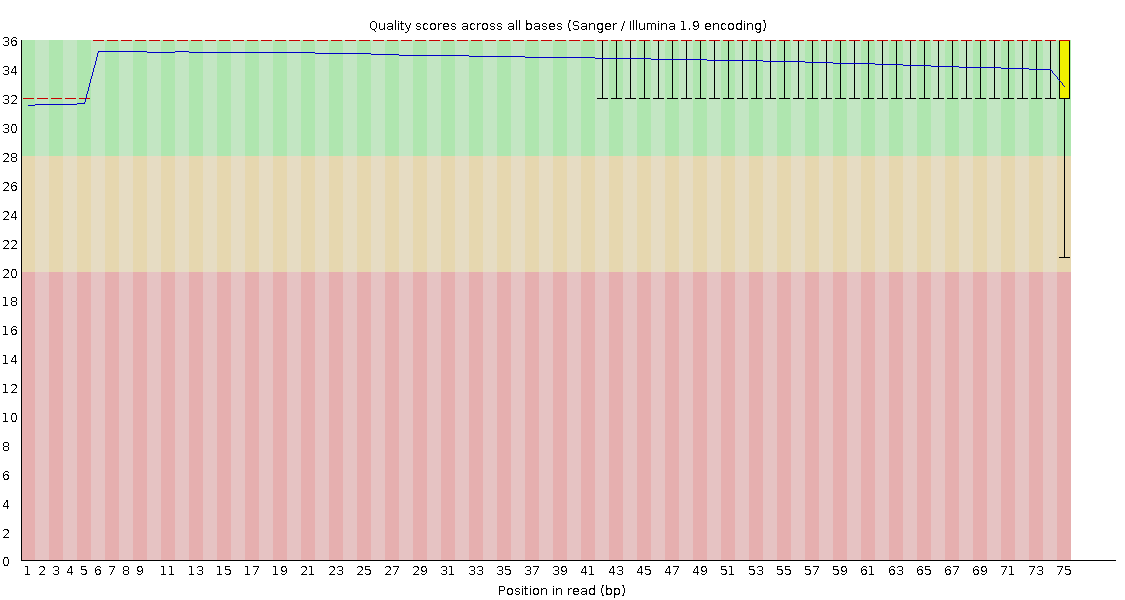

In [16]:
unzip -o -q fastqc/FOXA1HNF4A_U1_1_fastqc.zip -d fastqc
display < fastqc/FOXA1HNF4A_U1_1_fastqc/Images/per_base_quality.png

In this case sequencing quality looks good, for almost all bases the quality is above 30 (green part of the plot).

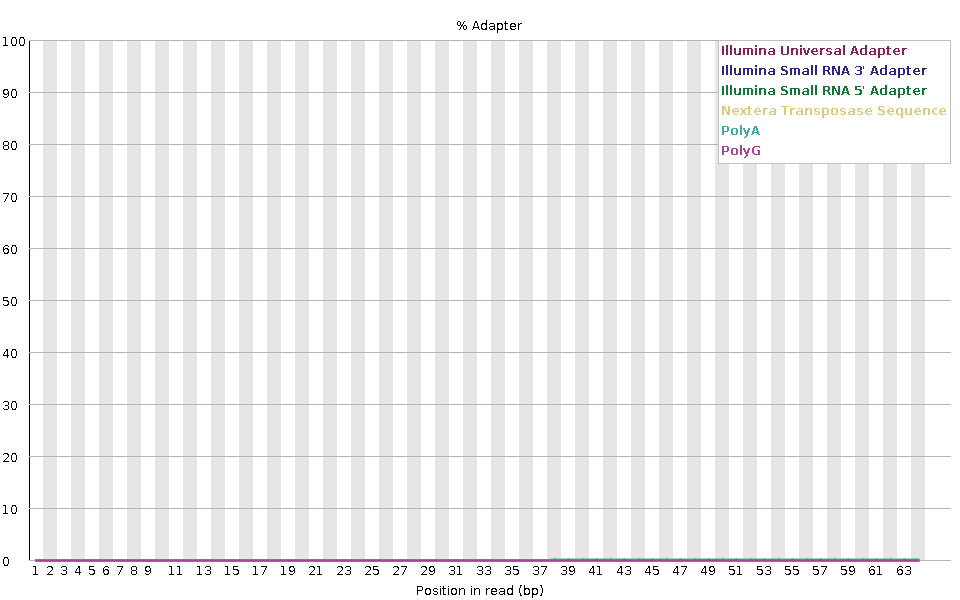

In [17]:
display < fastqc/FOXA1HNF4A_U1_1_fastqc/Images/adapter_content.png

This plot shows, for each position in the read, the percentage of reads that contain an adapter sequence up to that position. Adapters are sequenced when the cDNA fragment is shorter than the read length: the sequencer reads through the fragment into the adapter.

In this case there is (almost) no adapter contamination: less than 0.03% of the reads contain the Illumina Universal Adapter. The line that slowly increases towards the end of the reads is "PolyA" (stretches of A's, e.g. from the polyA tail of mRNAs), but this is also less than 0.3% of the reads. This is expected, because the libraries were size selected and our reads (75 bp) are much shorter than most cDNA fragments.

If your data does contain adapters, these can be trimmed away before alignment using tools like [cutadapt](https://cutadapt.readthedocs.io/en/stable/). The aligner we will use (STAR) can also deal with a few adapter bases using *soft-clipping*: bases at the end of a read that do not match the genome are not used in the alignment.

FastQC also gives a summary of all modules (PASS, WARN or FAIL):

In [18]:
cat fastqc/FOXA1HNF4A_U1_1_fastqc/summary.txt

PASS	Basic Statistics	FOXA1HNF4A_U1_1.fastq.gz


PASS	Per base sequence quality	FOXA1HNF4A_U1_1.fastq.gz


PASS	Per tile sequence quality	FOXA1HNF4A_U1_1.fastq.gz


PASS	Per sequence quality scores	FOXA1HNF4A_U1_1.fastq.gz


FAIL	Per base sequence content	FOXA1HNF4A_U1_1.fastq.gz


...

PASS	Per base N content	FOXA1HNF4A_U1_1.fastq.gz


PASS	Sequence Length Distribution	FOXA1HNF4A_U1_1.fastq.gz


FAIL	Sequence Duplication Levels	FOXA1HNF4A_U1_1.fastq.gz


PASS	Overrepresented sequences	FOXA1HNF4A_U1_1.fastq.gz


PASS	Adapter Content	FOXA1HNF4A_U1_1.fastq.gz


**Question**: Why do you think "Per base sequence content" and "Sequence Duplication Levels" get a warning/fail for RNA-seq data? (Hint: have a look at the documentation of these modules, linked above).

We have 36 fastq files, looking at all these reports one by one is not very practical. [MultiQC](https://multiqc.info/) collects the results of many tools (FastQC, STAR, featureCounts, ...) in a single report.

Let's first run FastQC on all files (this takes ~ 15 minutes).

In [ ]:
fastqc -t 18 --outdir fastqc fastq_files/*.fastq.gz

In [19]:
# -o: output directory
# -f: overwrite existing reports
multiqc -f -o multiqc_fastqc fastqc 2> /dev/null
ls multiqc_fastqc

multiqc_data  multiqc_report.html


Open `multiqc_fastqc/multiqc_report.html` in your browser. MultiQC also stores the summary statistics in a text file:

In [20]:
# Total Sequences, GC content, percentage of reads left after removing duplicates and average sequence length for each fastq file
# -s $'\t': only use tabs to separate columns (the column name "Total Sequences" contains a space)
cut -f 1,5,10,11,12 multiqc_fastqc/multiqc_data/multiqc_fastqc.txt | column -t -s $'\t'

Sample           Total Sequences  %GC   total_deduplicated_percentage  avg_sequence_length


FOXA1HNF4A_I1_1  81056038.0       47.0  33.413242707534344             75.0


FOXA1HNF4A_I1_2  81056038.0       48.0  32.915145406219665             75.0


FOXA1HNF4A_I2_1  78497223.0       48.0  32.72538164826827              75.0


FOXA1HNF4A_I2_2  78497223.0       48.0  32.322455431389216             75.0


...

HNF4A_U1_2       35819891.0       49.0  42.68079318205189              75.0


HNF4A_U2_1       36425095.0       48.0  41.48769392862634              75.0


HNF4A_U2_2       36425095.0       49.0  41.60279992553409              75.0


HNF4A_U3_1       30933872.0       48.0  44.38917317868318              75.0


HNF4A_U3_2       30933872.0       49.0  44.34912732959223              75.0


All samples look similar: all reads are 75 bp long and have a GC content of 47 - 49%. Only 32 - 45% of the reads remain after removing duplicates, so more than half of the reads are duplicates. As mentioned above, this is expected for RNA-seq data: highly expressed genes produce many identical reads.

Note that the FOXA1-HNF4A samples were sequenced about twice as deep as the other samples.

## Step 3: aligning reads to a reference genome

Next we will align the reads to the genome. For this we need an alignment tool. Many of such tools exist, in this exercise we will use [STAR](https://github.com/alexdobin/STAR).

RNA-seq reads come from mature mRNA, in which the introns have been spliced out. A read can thus span an exon-exon junction, meaning that part of the read maps to one exon and the rest of the read maps to the next exon, possibly thousands of bases further in the genome. STAR is a *splice aware* aligner: it can split a read over multiple exons.

```
genome:   ====[exon 1]-------------intron-------------[exon 2]====
read:         ------>                                  ---->
              (part 1 of the read)                     (part 2 of the read)
```

In order to be able to run STAR it first needs to create an index (a database) of the reference genome of interest. In this case we want to map the reads to the human reference genome (GRCh38, also called hg38). We use the genome sequence and gene annotation of [GENCODE](https://www.gencodegenes.org/human/) (release 46).

    https://ftp.ebi.ac.uk/pub/databases/gencode/Gencode_human/release_46/GRCh38.primary_assembly.genome.fa.gz
    https://ftp.ebi.ac.uk/pub/databases/gencode/Gencode_human/release_46/gencode.v46.primary_assembly.annotation.gtf.gz

STAR uses the gene annotation (gtf file, see below) to know where the exon-exon junctions are. This improves the alignment of reads spanning a junction.

Creating such an index takes a long time (~1 hour) and requires a lot of memory (~32 GB). The index is stored in `${GENOME_DIR}/GRCh38.gencode_v46.star_d`.

- `--sjdbOverhang 74`: the length of the sequence around annotated junctions used to build the index, ideally this is read length - 1 (our reads are 75 bp).

In [ ]:
mkdir -p ${GENOME_DIR}
cd ${GENOME_DIR}
wget https://ftp.ebi.ac.uk/pub/databases/gencode/Gencode_human/release_46/GRCh38.primary_assembly.genome.fa.gz
wget https://ftp.ebi.ac.uk/pub/databases/gencode/Gencode_human/release_46/gencode.v46.primary_assembly.annotation.gtf.gz
gunzip -k GRCh38.primary_assembly.genome.fa.gz
gunzip -k gencode.v46.primary_assembly.annotation.gtf.gz
STAR \
    --runMode genomeGenerate \
    --runThreadN 12 \
    --genomeDir GRCh38.gencode_v46.star_d \
    --genomeFastaFiles GRCh38.primary_assembly.genome.fa \
    --sjdbGTFfile gencode.v46.primary_assembly.annotation.gtf \
    --sjdbOverhang 74
cd -

STAR has very extensive documentation that can be found in [its manual](https://github.com/alexdobin/STAR/blob/master/doc/STARmanual.pdf).

Let's create an output directory for the alignment files and run STAR on our test files. For paired-end data we give both fastq files to `--readFilesIn` (first read 1, then read 2).

In [21]:
mkdir -p alignment_test
STAR \
    --genomeDir ${GENOME_DIR}/GRCh38.gencode_v46.star_d \
    --runThreadN 4 \
    --readFilesIn fastq_files_test/SRR15477602_1.fastq fastq_files_test/SRR15477602_2.fastq \
    --outFileNamePrefix alignment_test/test.

	STAR --genomeDir genome/GRCh38.gencode_v46.star_d --runThreadN 4 --readFilesIn fastq_files_test/SRR15477602_1.fastq fastq_files_test/SRR15477602_2.fastq --outFileNamePrefix alignment_test/test.


	STAR version: 2.7.10b   compiled: 2022-11-01T09:53:26-04:00 :/home/dobin/data/STAR/STARcode/STAR.master/source


Oct 28 14:30:38 ..... started STAR run


Oct 28 14:30:38 ..... loading genome


Oct 28 14:30:55 ..... started mapping


Oct 28 14:30:56 ..... finished mapping


Oct 28 14:30:58 ..... finished successfully


In [22]:
ls alignment_test

test.Aligned.out.bam      test.SJ.out.tab


test.Aligned.out.bam.bai  test.bam_directly.Aligned.sortedByCoord.out.bam


test.Aligned.out.sam      test.bam_directly.Log.final.out


test.Log.final.out        test.bam_directly.Log.out


test.Log.out              test.bam_directly.Log.progress.out


test.Log.progress.out     test.bam_directly.SJ.out.tab


STAR will generate several files:
- A file containing the actual alignment (test.Aligned.out.sam)
- A log file containing information on the alignment (test.Log.final.out)
- A file containing all detected splice junctions (test.SJ.out.tab)
- Several other log files.

In [23]:
cat alignment_test/test.Log.final.out

                                 Started job on |	Oct 28 14:30:38


                             Started mapping on |	Oct 28 14:30:55


                                    Finished on |	Oct 28 14:30:58


       Mapping speed, Million of reads per hour |	12.00


                          Number of input reads |	10000


...

                Number of reads unmapped: other |	7


                     % of reads unmapped: other |	0.07%


                                  CHIMERIC READS:


                       Number of chimeric reads |	0


                            % of chimeric reads |	0.00%


Most important are:
- **Uniquely mapped reads %**: the percentage of reads that map to exactly one location in the genome. For RNA-seq this should be > 70 - 80%.
- **% of reads mapped to multiple loci**: reads that map equally well to multiple locations (e.g. repeats, gene families), these are typically not used for counting.
- **% of reads unmapped: too short**: reads for which only a small part could be aligned (e.g. because of adapters or contamination).
- **Number of splices: Total**: the number of reads that span an exon-exon junction.

In [24]:
cat alignment_test/test.Aligned.out.sam | head -n 30

@HD	VN:1.4


@SQ	SN:chr1	LN:248956422


@SQ	SN:chr2	LN:242193529


@SQ	SN:chr3	LN:198295559


@SQ	SN:chr4	LN:190214555


...

@SQ	SN:chrM	LN:16569


@SQ	SN:GL000008.2	LN:209709


@SQ	SN:GL000009.2	LN:201709


@SQ	SN:GL000194.1	LN:191469


@SQ	SN:GL000195.1	LN:182896


The SAM file starts with a heading section, the headings always begin with the "@" symbol (you can ignore the Broken pipe errors). The `@SQ` lines list all chromosomes (and their length), the `@PG` line shows the command that was used to generate the file.

In [25]:
cat alignment_test/test.Aligned.out.sam | grep -v "^@" | head -n 2

SRR15477602.62	163	chr19	3575615	255	1S46M600N28M	=	3577033	1493	NTATAAGATGTGCACGGAGAAGATCCAGGAGNNGNAGATCANGAAAGNAGACTCGAGCTNTGGGCTCATGAACAC	#//A/A/A6E/E//EEAAA/AE//EE/EE6/##E#EEE/EE#E/E//#EE66E///E<E#EE/EA///</E/E/E	NH:i:1	HI:i:1	AS:i:141	nM:i:0


SRR15477602.62	83	chr19	3577033	255	75M	=	3575615	-1493	CGCTGGCGCTGCAGCAGCAGCTCCAGGCCGTGCGCCAGGCGCTCACCGCCAGCTTCGCCTCACTGCCGGNGCCGG	E/A/EEEEE//<EEEEEEEEE/EAEEEEEE/AEEEAEAEEEEEEEE<EE<AEE/EAEEE6EAE/AEEE/#AAAA/	NH:i:1	HI:i:1	AS:i:141	nM:i:0


The actual alignment section (not starting with the "@" symbol) has 11 mandatory fields (columns) and each read is represented as a single row. For paired-end data the two mates of a pair are on consecutive rows.

The fields are:
1. QNAME: Query template name (the read identifier, the same for both mates)
2. FLAG: bitwise FLAG
3. RNAME: Reference sequence NAME (chromosome)
4. POS: 1-based leftmost mapping POSition
5. MAPQ: mapping quality (STAR: 255 = unique, 3 = maps to 2 locations, 1 = maps to 3-4 locations, 0 = maps to more than 4 locations)
6. CIGAR: CIGAR string
7. RNEXT: Ref. name of the mate/next read (`=` means same chromosome)
8. PNEXT: Position of the mate/next read
9. TLEN: observed Template LENgth (the length of the cDNA fragment!)
10. SEQ: segment sequence
11. QUAL: ASCII of Phred-scaled base QUALity+33

There can be further optional fields (SAM tags).

These are represented like this

    <TAG>:<type>:<value>

With the type being one of the following: A (character), B (general array), f (real number), H (hexadecimal array), i (integer), or Z (string).

- NH:i Number of reported alignments that contain the query in the current record
- HI:i Query hit index
- AS:i Alignment score generated by aligner
- nM:i Number of mismatches (for both mates combined)

**The CIGAR string** describes how the read aligns to the genome, e.g. `30M1500N45M` means: 30 bases match, then skip 1500 bases of the genome (`N`, an intron!), then 45 bases match. Other operations are `I` (insertion), `D` (deletion) and `S` (soft-clipped, not aligned).

**The bitwise FLAG** encodes several properties of the read as a sum of powers of 2. For paired-end data the most common flags are:

| FLAG | meaning |
|---|---|
| 99 = 1 + 2 + 32 + 64 | read paired, mapped in proper pair, mate on reverse strand, first in pair (read 1) |
| 147 = 1 + 2 + 16 + 128 | read paired, mapped in proper pair, read on reverse strand, second in pair (read 2) |
| 83 = 1 + 2 + 16 + 64 | read paired, mapped in proper pair, read on reverse strand, first in pair (read 1) |
| 163 = 1 + 2 + 32 + 128 | read paired, mapped in proper pair, mate on reverse strand, second in pair (read 2) |

For more information on these fields see: https://en.wikipedia.org/wiki/SAM_(file_format)
To decode bitwise flags see: https://www.samformat.info/sam-format-flag

**Question**: Try to interpret the two reads displayed above. Which one is read 1? On which strand do they map? What is the length of the cDNA fragment? Can you explain the CIGAR string `1S46M600N28M`?

Let's look for a read that spans an exon-exon junction (an `N` in the CIGAR string, column 6).

In [26]:
cat alignment_test/test.Aligned.out.sam | grep -v "^@" | awk '$6 ~ /N/' | head -n 2 | cut -f 1-9

SRR15477602.62	163	chr19	3575615	255	1S46M600N28M	=	3577033	1493


SRR15477602.63	163	chrX	154398498	255	1S45M795N29M	=	154399520	1097


SAM files are plain text files. For this reason they take a lot of space. For this reason we usually don't store plain SAM files on disk but convert them to BAM files (which is a binary, compressed, file). To do this the file has to be sorted first (based on genomic position), both the sorting and converting to BAM can be accomplished using samtools.

In [27]:
#-O output a BAM file
#-o name of the bam file
samtools sort alignment_test/test.Aligned.out.sam \
    -O BAM \
    -o alignment_test/test.Aligned.out.bam

In [28]:
ls -lhgG alignment_test/

total 9.4M


-rw-r--r-- 1 1.2M Oct 28 14:30 test.Aligned.out.bam


-rw-r--r-- 1 1.6M Oct 28 14:02 test.Aligned.out.bam.bai


-rw-r--r-- 1 5.0M Oct 28 14:30 test.Aligned.out.sam


-rw-r--r-- 1 2.0K Oct 28 14:30 test.Log.final.out


...

-rw-r--r-- 1 1.4M Oct 28 14:02 test.bam_directly.Aligned.sortedByCoord.out.bam


-rw-r--r-- 1 2.0K Oct 28 14:02 test.bam_directly.Log.final.out


-rw-r--r-- 1  12K Oct 28 14:02 test.bam_directly.Log.out


-rw-r--r-- 1  246 Oct 28 14:02 test.bam_directly.Log.progress.out


-rw-r--r-- 1 145K Oct 28 14:02 test.bam_directly.SJ.out.tab


As you can see, the bam file is a lot smaller than the sam file.
In order to quickly inspect bam files (for example in IGV, see below) we need to index the file. Again we use samtools for this.

In [29]:
samtools index alignment_test/test.Aligned.out.bam

In fact we can actually instruct STAR to directly output a sorted bam file instead of generating a sam file.

In [30]:
STAR \
    --genomeDir ${GENOME_DIR}/GRCh38.gencode_v46.star_d \
    --runThreadN 4 \
    --readFilesIn fastq_files_test/SRR15477602_1.fastq fastq_files_test/SRR15477602_2.fastq \
    --outFileNamePrefix alignment_test/test.bam_directly. \
    --outSAMtype BAM SortedByCoordinate

	STAR --genomeDir genome/GRCh38.gencode_v46.star_d --runThreadN 4 --readFilesIn fastq_files_test/SRR15477602_1.fastq fastq_files_test/SRR15477602_2.fastq --outFileNamePrefix alignment_test/test.bam_directly. --outSAMtype BAM SortedByCoordinate


	STAR version: 2.7.10b   compiled: 2022-11-01T09:53:26-04:00 :/home/dobin/data/STAR/STARcode/STAR.master/source


Oct 28 14:30:59 ..... started STAR run


Oct 28 14:30:59 ..... loading genome


Oct 28 14:31:16 ..... started mapping


Oct 28 14:31:17 ..... finished mapping


Oct 28 14:31:19 ..... started sorting BAM


Oct 28 14:31:19 ..... finished successfully


In [31]:
ls -lhgG alignment_test/

total 9.4M


-rw-r--r-- 1 1.2M Oct 28 14:30 test.Aligned.out.bam


-rw-r--r-- 1 1.6M Oct 28 14:30 test.Aligned.out.bam.bai


-rw-r--r-- 1 5.0M Oct 28 14:30 test.Aligned.out.sam


-rw-r--r-- 1 2.0K Oct 28 14:30 test.Log.final.out


...

-rw-r--r-- 1 1.4M Oct 28 14:31 test.bam_directly.Aligned.sortedByCoord.out.bam


-rw-r--r-- 1 2.0K Oct 28 14:31 test.bam_directly.Log.final.out


-rw-r--r-- 1  12K Oct 28 14:31 test.bam_directly.Log.out


-rw-r--r-- 1  246 Oct 28 14:31 test.bam_directly.Log.progress.out


-rw-r--r-- 1 145K Oct 28 14:31 test.bam_directly.SJ.out.tab


Using samtools we can also inspect bam files.

For example we can view the bam file:

In [32]:
samtools view alignment_test/test.Aligned.out.bam | head -n 1

SRR15477602.7004	355	chr1	17525	3	75M	=	17998	754	CCTGTGTCTGATGCCCTGGGTCCCCACTAAGCCAGGCCGGGCCTCCCGCCCACACCCCTCGGCCCTGCCCTCAGG	AAAAAEEEEEEEE/A/AA/EEE/EEE<EEE6AAAEEA///AE//AEE/AEEEE/E6<E/EEEEAE//EE</6/EE	NH:i:2	HI:i:2	AS:i:148	nM:i:1


We can see how many reads mapped to each chromosome:

In [33]:
samtools idxstats alignment_test/test.Aligned.out.bam | head -n 25
# this commands outputs a tab delimited file with the following columns:
# Col 1 chromosome name
# Col 2 length of the chromosome
# Col 3 number of reads mapped to this chromosome
# Col 4 number of unmapped read fragments

chr1	248956422	2506	0


chr2	242193529	1170	0


chr3	198295559	856	0


chr4	190214555	558	0


chr5	181538259	900	0


...

chr21	46709983	508	0


chr22	50818468	452	0


chrX	156040895	650	0


chrY	57227415	18	0


chrM	16569	1214	0


We can get info on the different SAM flags present in the file:

In [34]:
samtools flagstat alignment_test/test.Aligned.out.bam

21318 + 0 in total (QC-passed reads + QC-failed reads)


19462 + 0 primary


1856 + 0 secondary


0 + 0 supplementary


0 + 0 duplicates


...

19462 + 0 properly paired (100.00% : N/A)


19462 + 0 with itself and mate mapped


0 + 0 singletons (0.00% : N/A)


0 + 0 with mate mapped to a different chr


0 + 0 with mate mapped to a different chr (mapQ>=5)


**Question**: We downloaded 10000 read pairs, but samtools reports 21318 alignments in total, of which 19462 are "primary" and 1856 are "secondary". Can you explain these numbers? (Hint: how many reads are there in a read pair? What happens with reads that map to multiple locations? Which reads are missing from the BAM file?)

Let's align all reads to the reference genome. Aligning one sample takes ~ 5-10 minutes using 20 threads.

- `--readFilesCommand zcat`: our fastq files are compressed, this tells STAR to decompress them using `zcat`.
- `--genomeLoad LoadAndKeep`: load the genome index in memory only once and keep it there for the next samples (this saves a lot of time).
- `--limitBAMsortRAM`: amount of memory that can be used for sorting the BAM file (required with `LoadAndKeep`).

In [ ]:
mkdir -p alignment

In [ ]:
for SAMPLE_NAME in $(cut -f 2 samples.tsv)                  #Loop over all sample names (second column of samples.tsv)
do
    echo -e "Aligning ${SAMPLE_NAME}"
    STAR \
        --genomeDir ${GENOME_DIR}/GRCh38.gencode_v46.star_d \
        --runThreadN 20 \
        --readFilesIn fastq_files/${SAMPLE_NAME}_1.fastq.gz fastq_files/${SAMPLE_NAME}_2.fastq.gz \
        --readFilesCommand zcat \
        --genomeLoad LoadAndKeep \
        --limitBAMsortRAM 30000000000 \
        --outFileNamePrefix alignment/${SAMPLE_NAME}. \
        --outSAMtype BAM SortedByCoordinate
done
STAR --genomeDir ${GENOME_DIR}/GRCh38.gencode_v46.star_d --genomeLoad Remove --outFileNamePrefix alignment/remove_genome. #remove the genome from memory
rm alignment/remove_genome.*                                        #remove the (empty) output files of the previous command

Let's have a look at the alignment files.

In [35]:
ls -lhgG alignment/*.bam

-rw-r--r-- 1 6.3G Oct 28 11:20 alignment/FOXA1HNF4A_I1.Aligned.sortedByCoord.out.bam


-rw-r--r-- 1 6.0G Oct 28 11:27 alignment/FOXA1HNF4A_I2.Aligned.sortedByCoord.out.bam


-rw-r--r-- 1 5.7G Oct 28 11:34 alignment/FOXA1HNF4A_I3.Aligned.sortedByCoord.out.bam


-rw-r--r-- 1 5.4G Oct 28 11:01 alignment/FOXA1HNF4A_U1.Aligned.sortedByCoord.out.bam


-rw-r--r-- 1 5.5G Oct 28 11:07 alignment/FOXA1HNF4A_U2.Aligned.sortedByCoord.out.bam


...

-rw-r--r-- 1 3.5G Oct 28 10:51 alignment/HNF4A_I2.Aligned.sortedByCoord.out.bam


-rw-r--r-- 1 2.8G Oct 28 10:54 alignment/HNF4A_I3.Aligned.sortedByCoord.out.bam


-rw-r--r-- 1 3.1G Oct 28 10:35 alignment/HNF4A_U1.Aligned.sortedByCoord.out.bam


-rw-r--r-- 1 3.3G Oct 28 10:40 alignment/HNF4A_U2.Aligned.sortedByCoord.out.bam


-rw-r--r-- 1 2.9G Oct 28 10:43 alignment/HNF4A_U3.Aligned.sortedByCoord.out.bam


Let's check the percentage of uniquely mapped reads for all samples.

In [36]:
grep "Uniquely mapped reads %" alignment/*.Log.final.out | sed "s/alignment\///g" | sed "s/.Log.final.out:\s*Uniquely mapped reads % |//g" | column -t

FOXA1HNF4A_I1  93.20%


FOXA1HNF4A_I2  93.60%


FOXA1HNF4A_I3  93.38%


FOXA1HNF4A_U1  93.19%


FOXA1HNF4A_U2  93.11%


...

HNF4A_I2       93.28%


HNF4A_I3       91.68%


HNF4A_U1       92.08%


HNF4A_U2       92.45%


HNF4A_U3       92.31%


For all samples more than 90% of the reads map uniquely to the genome. This is very good.

MultiQC can also summarize the STAR log files:

In [37]:
multiqc -f -o multiqc_star alignment 2> /dev/null
cut -f 1-5 multiqc_star/multiqc_data/multiqc_star.txt | column -t

Sample         total_reads  avg_input_read_length  uniquely_mapped  uniquely_mapped_percent


FOXA1HNF4A_I1  81056038.0   150.0                  75545963.0       93.2


FOXA1HNF4A_I2  78497223.0   150.0                  73473500.0       93.6


FOXA1HNF4A_I3  75886936.0   150.0                  70860336.0       93.38


FOXA1HNF4A_U1  71081834.0   150.0                  66241059.0       93.19


...

HNF4A_I2       40301797.0   150.0                  37595221.0       93.28


HNF4A_I3       29380066.0   150.0                  26934786.0       91.68


HNF4A_U1       35819891.0   150.0                  32983526.0       92.08


HNF4A_U2       36425095.0   150.0                  33674234.0       92.45


HNF4A_U3       30933872.0   150.0                  28556074.0       92.31


## Step 4: visualize data in a genome browser (IGV)

The aligned reads can be visualized in a genome browser for example using [IGV](https://igv.org/).

For this the bam files first need to be indexed.

In [38]:
for bam_file in alignment/*.bam
do
    echo "Indexing: ${bam_file}"
    samtools index -@ 4 -b ${bam_file}
done

Indexing: alignment/FOXA1HNF4A_I1.Aligned.sortedByCoord.out.bam


Indexing: alignment/FOXA1HNF4A_I2.Aligned.sortedByCoord.out.bam


Indexing: alignment/FOXA1HNF4A_I3.Aligned.sortedByCoord.out.bam


Indexing: alignment/FOXA1HNF4A_U1.Aligned.sortedByCoord.out.bam


Indexing: alignment/FOXA1HNF4A_U2.Aligned.sortedByCoord.out.bam


...

Indexing: alignment/HNF4A_I2.Aligned.sortedByCoord.out.bam


Indexing: alignment/HNF4A_I3.Aligned.sortedByCoord.out.bam


Indexing: alignment/HNF4A_U1.Aligned.sortedByCoord.out.bam


Indexing: alignment/HNF4A_U2.Aligned.sortedByCoord.out.bam


Indexing: alignment/HNF4A_U3.Aligned.sortedByCoord.out.bam


Download both the bam files (`.bam`) and the index (`.bam.bai`) of FOXA1HNF4A_U1 and FOXA1HNF4A_I1 to your computer and load the bam files in IGV (make sure the genome is set to hg38).

Have a look at the following genes:

- **ALB** (albumin), the most abundant protein in blood plasma, made by the liver. Shown in Figure 1C of the paper.
- **APOA2** and **APOH**, apolipoproteins made by the liver.
- **FOXA1** and **HNF4A**: the transgenes.

Note that:

- The coverage is much higher in the induced vs uninduced condition
- Reads span the exons of the gene but not the introns (can you explain why this is the case?)
- Some reads are split over two exons (shown as a thin line connecting two blocks in IGV)

We can also count the number of reads in a genomic region directly using samtools. For example the ALB gene is located at chr4:73,404,256-73,421,482:

In [39]:
for sample in FOXA1HNF4A_U1 FOXA1HNF4A_U2 FOXA1HNF4A_U3 FOXA1HNF4A_I1 FOXA1HNF4A_I2 FOXA1HNF4A_I3
do
    # -c: count the reads instead of printing them
    # -q 255: only count uniquely mapped reads
    echo -e "${sample}\t$(samtools view -c -q 255 alignment/${sample}.Aligned.sortedByCoord.out.bam chr4:73404256-73421482)"
done

FOXA1HNF4A_U1	22


FOXA1HNF4A_U2	42


FOXA1HNF4A_U3	24


FOXA1HNF4A_I1	4745


FOXA1HNF4A_I2	4633


FOXA1HNF4A_I3	4478


ALB is almost not expressed in uninduced K562 cells but is strongly activated (> 100 fold) upon induction of FOXA1 and HNF4A!

Let's also look at the transgenes. First HNF4A (chr20:44,355,699-44,432,845).

In [40]:
for sample in FOXA1HNF4A_U1 FOXA1HNF4A_U2 FOXA1HNF4A_U3 FOXA1HNF4A_I1 FOXA1HNF4A_I2 FOXA1HNF4A_I3
do
    echo -e "${sample}\t$(samtools view -c -q 255 alignment/${sample}.Aligned.sortedByCoord.out.bam chr20:44355699-44432845)"
done

FOXA1HNF4A_U1	531


FOXA1HNF4A_U2	611


FOXA1HNF4A_U3	445


FOXA1HNF4A_I1	121801


FOXA1HNF4A_I2	117056


FOXA1HNF4A_I3	115548


HNF4A is strongly induced upon doxycycline treatment. The transgene is a cDNA of the coding sequence (open reading frame, ORF) of the human *HNF4A* gene, so reads coming from the transgene map to the exons of the endogenous *HNF4A* gene. Because the transgene does not contain the untranslated regions (UTRs), you will see in IGV that the coverage is mainly on the coding part of the gene.

Next, FOXA1 (chr14:37,589,552-37,595,249).

In [41]:
for sample in FOXA1HNF4A_U1 FOXA1HNF4A_U2 FOXA1HNF4A_U3 FOXA1HNF4A_I1 FOXA1HNF4A_I2 FOXA1HNF4A_I3
do
    echo -e "${sample}\t$(samtools view -c -q 255 alignment/${sample}.Aligned.sortedByCoord.out.bam chr14:37589552-37595249)"
done

FOXA1HNF4A_U1	247


FOXA1HNF4A_U2	252


FOXA1HNF4A_U3	228


FOXA1HNF4A_I1	66


FOXA1HNF4A_I2	64


FOXA1HNF4A_I3	70


Surprisingly, there are *fewer* reads mapping to FOXA1 in the induced samples! Did the induction of FOXA1 fail?

No, the transgene is expressed, but its reads do not map to the *FOXA1* gene. The FOXA1 ORF that was used (Addgene #120438) has a different DNA sequence than the endogenous gene, it is (most likely) **codon optimized**: it encodes exactly the same FOXA1 protein, but uses different (synonymous) codons. Codon optimization is often used to increase protein expression or to distinguish a transgene from the endogenous gene.

We can show this by searching the reads of an induced sample for sequences that encode the FOXA1 protein (by translating the reads in all 6 reading frames). Here is one of these reads (read 1 of FOXA1_I1), compared to the sequence of the endogenous *FOXA1* gene:

```
protein  : G  N  M  F  E  N  G  C  Y  L  R  R  Q  K  R  F  K  C  E  K  Q  P  G  A      (FOXA1 amino acids 251 - 274)
read     : GGCAATATGTTCGAGAATGGTTGTTATCTTAGACGGCAGAAACGATTCAAATGTGAGAAACAGCCAGGTGCC
genome   : GGCAACATGTTCGAGAACGGCTGCTACTTGCGCCGCCAGAAGCGCTTCAAGTGCGAGAAGCAGCCGGGGGCC
           ||||| ||||||||||| || || ||  |  | || ||||| || ||||| || ||||| ||||| || |||      17 mismatches
```

Both sequences encode the same amino acids, but they differ at 17 out of 72 positions, almost always at the third base of a codon. With so many mismatches STAR cannot align these reads to the genome (by default STAR allows at most 10 mismatches per read pair). In the first 3 million reads of FOXA1_I1 we found 662 reads that encode the FOXA1 protein, while only 15 such reads were found in FOXA1_U1.

So, with our approach we can **not** measure the expression of the FOXA1 transgene, but we can measure the expression of HNF4A. The reads that map to the *FOXA1* gene come from the endogenous gene (they also cover the UTRs).

**Question**: How could you adapt the analysis such that you can measure the expression of the FOXA1 transgene? (Hint: what would you have to add to the reference genome and the gtf file?)

**Question**: There are already some reads mapping to HNF4A in the uninduced samples. Can you think of an explanation? (Hint: K562 cells express a low amount of endogenous HNF4A. Also, how does a Tet-On system work? Is it completely "off" without doxycycline?)

## Step 5: count number of reads overlapping each gene.

Before we can start with differential expression analysis we need to count, for each sample separately, how many reads overlap each gene. This will generate a count matrix which we can use for identifying genes for which the expression is different between our two conditions.

For this we will use the program:

    featureCounts

and we will need a gtf file.

A GTF file is a file containing genomic features (like genes, exons, introns, ...) along with their genomic locations and other metadata. This is a tab-separated file containing the following fields:

1. seqname: name of the chromosome (or scaffold)
2. source: name of the program that generated this feature or the data source
3. feature: the type of feature (gene, transcript, exon, CDS, UTR, ...)
4. start: genomic start position of the feature
5. end: genomic end position of the feature
6. score: a floating point value of the score of the feature (optional)
7. strand: whether the feature is on the forward (+) or reverse (-) strand.
8. frame: One of '0', '1' or '2'. '0' indicates that the first base of the feature is the first base of a codon, '1' that the second base is the first base of a codon, and so on..
9. attribute: a semicolon (;) separated list of tag value pairs containing additional information

see https://www.ensembl.org/info/website/upload/gff.html for more information.

We will use the GENCODE gtf file (the same file we used to build the STAR index).

In [42]:
ln -sf ${GENOME_DIR}/gencode.v46.primary_assembly.annotation.gtf.gz .

In [43]:
zcat gencode.v46.primary_assembly.annotation.gtf.gz | head -n 7

##description: evidence-based annotation of the human genome (GRCh38), version 46 (Ensembl 112)


##provider: GENCODE


##contact: gencode-help@ebi.ac.uk


##format: gtf


##date: 2024-03-26


chr1	HAVANA	gene	11869	14409	.	+	.	gene_id "ENSG00000290825.1"; gene_type "lncRNA"; gene_name "DDX11L2"; level 2; tag "overlaps_pseudogene";


chr1	HAVANA	transcript	11869	14409	.	+	.	gene_id "ENSG00000290825.1"; transcript_id "ENST00000456328.2"; gene_type "lncRNA"; gene_name "DDX11L2"; transcript_type "lncRNA"; transcript_name "DDX11L2-202"; level 2; transcript_support_level "1"; tag "basic"; tag "Ensembl_canonical"; havana_transcript "OTTHUMT00000362751.1";


The first 5 lines (starting with `#`) contain metadata. Next we see, for example:

    chr1	HAVANA	gene	11869	14409	.	+	.	gene_id "ENSG00000290825.1"; gene_type "lncRNA"; gene_name "DDX11L2"; ...

This is a gene located at chr1:11869-14409 on the positive strand. The gene is annotated by the HAVANA group, it has the gene_id ENSG00000290825.1 and gene name DDX11L2, and it is a long non-coding RNA (lncRNA).

By default featureCounts counts reads overlapping `exon` features and sums them per `gene_id`. Let's have a look at the exons of FOXA1.

In [44]:
zcat gencode.v46.primary_assembly.annotation.gtf.gz | awk '$3 == "exon"' | grep 'gene_name "FOXA1";' | cut -f 1,3,4,5,7

chr14	exon	37594901	37595249	-


chr14	exon	37589552	37592711	-


chr14	exon	37594076	37594262	-


chr14	exon	37591093	37592711	-


chr14	exon	37594901	37595110	-


...

chr14	exon	37592516	37592711	-


chr14	exon	37594901	37594950	-


chr14	exon	37593875	37594613	-


chr14	exon	37595993	37596059	-


chr14	exon	37595024	37595348	-


### Strandedness

The libraries were prepared with the *NEBNext Ultra II **Directional** RNA Library Prep Kit*. Directional (or stranded) libraries retain the information from which DNA strand the RNA was transcribed. This is important when two genes overlap on opposite strands.

For this kit (dUTP method) **read 2** has the same sequence as the RNA and read 1 is the reverse complement of the RNA (this is called *reverse stranded*).

featureCounts has an option for this:

    -s 0: unstranded
    -s 1: stranded (read 1 has the same sequence as the RNA)
    -s 2: reversely stranded (read 2 has the same sequence as the RNA)

If you are not sure how the library was prepared you can test this. Let's count the reads of a single sample with each of the three options and compare the number of assigned reads.

In [45]:
mkdir -p counts
for strand in 0 1 2
do
    #-p: paired-end data
    #--countReadPairs: count read pairs (fragments) instead of reads
    #-s: strandedness
    #-T 8: use 8 threads
    featureCounts \
        -p --countReadPairs \
        -s ${strand} \
        -T 8 \
        -a gencode.v46.primary_assembly.annotation.gtf.gz \
        -o counts/strand_test_s${strand}.counts \
        alignment/FOXA1HNF4A_U1.Aligned.sortedByCoord.out.bam 2> /dev/null > /dev/null
    echo -e "-s ${strand}\t$(grep -P "^Assigned\t" counts/strand_test_s${strand}.counts.summary | cut -f 2) assigned read pairs"
done

-s 0	57034969 assigned read pairs


-s 1	4079077 assigned read pairs


-s 2	58449147 assigned read pairs


With `-s 1` only few reads are assigned (reads are counted on the wrong strand), while with `-s 2` most reads are assigned. This confirms that the library is reversely stranded.

Note that with `-s 2` even more reads are assigned than with the unstranded option (`-s 0`). Without strand information, a read that overlaps two genes on opposite strands is *ambiguous* and will not be counted. With strand information, featureCounts knows which of the two genes the read comes from.

**Question**: Why does `-s 1` still assign some reads?

Let's count the reads overlapping the genes for all samples.

In [46]:
#-p --countReadPairs: count fragments (read pairs) instead of reads
#-s 2: reversely stranded library
#-Q 10: only count reads with a minimum mapping quality of 10 (i.e. reads that map uniquely)
#-g gene_name: use gene_name as feature names (you can also use gene_id, although this is less human readable)
#-a gencode.v46.primary_assembly.annotation.gtf.gz: specify the annotation file
#-o counts/foxa1_hnf4a.counts: specify the output file
#-T 8: use 8 threads
#alignment/*.bam count for all the bam files in the alignment folder
featureCounts \
    -p --countReadPairs \
    -s 2 \
    -Q 10 \
    -g gene_name \
    -T 8 \
    -a gencode.v46.primary_assembly.annotation.gtf.gz \
    -o counts/foxa1_hnf4a.counts \
    alignment/*.bam

        ==========     _____ _    _ ____  _____  ______          _____  


        =====         / ____| |  | |  _ \|  __ \|  ____|   /\   |  __ \ 


          =====      | (___ | |  | | |_) | |__) | |__     /  \  | |  | |


            ====      \___ \| |  | |  _ <|  _  /|  __|   / /\ \ | |  | |


              ====    ____) | |__| | |_) | | \ \| |____ / ____ \| |__| |


...

||                                                                            ||


|| Summary of counting results can be found in file "counts/foxa1_hnf4a.coun  ||


|| ts.summary"                                                                ||


||                                                                            ||


\\============================================================================//


As you can see, the program outputs some information on the amount of reads that overlap the features in the gtf file. Around 77% of the alignments are assigned to a gene. featureCounts also writes a summary file that gives the reason why reads were not assigned:

In [47]:
cat counts/foxa1_hnf4a.counts.summary \
    | sed "s/alignment\///g" \
    | sed "s/.Aligned.sortedByCoord.out.bam//g" \
    | awk '{s=0; for(i=2;i<=NF;i++) s+=$i; if (NR==1 || s > 0) print}' \
    | column -t

Status                   FOXA1HNF4A_I1  FOXA1HNF4A_I2  FOXA1HNF4A_I3  FOXA1HNF4A_U1  FOXA1HNF4A_U2  FOXA1HNF4A_U3  FOXA1_I1  FOXA1_I2  FOXA1_I3  FOXA1_U1  FOXA1_U2  FOXA1_U3  HNF4A_I1  HNF4A_I2  HNF4A_I3  HNF4A_U1  HNF4A_U2  HNF4A_U3


Assigned                 67069366       65780794       62588294       58525899       58790569       48266704       32117999  24619887  24708460  23625877  30555032  23225451  29793452  33727130  24434640  29558349  30361726  25681018


Unassigned_MultiMapping  13217402       11100864       8956662        10289978       11179045       8696076        5709556   4307595   4471396   4008225   5321441   3804289   4934341   6052223   6066976   6129948   6401432   5643486


Unassigned_NoFeatures    5563081        4797324        5539590        4858028        4458259        3584235        2377633   1783950   1909944   1611167   2020863   1518519   2031724   2401611   1371226   2012434   1823790   1620970


Unassigned_Ambiguity     2913516        2895382        2732452        2857132        2892699        2324948        1393746   1048319   1047431   1109414   1491074   1070011   1314808   1466480   1128920   1412743   1488718   1254086


- Unassigned_MultiMapping / Unassigned_MappingQuality: reads that map to multiple locations
- Unassigned_NoFeatures: reads that do not overlap any exon (e.g. intronic or intergenic reads)
- Unassigned_Ambiguity: reads that overlap more than one gene

In [48]:
ls counts

foxa1_hnf4a.counts             strand_test_s1.counts


foxa1_hnf4a.counts.formatted   strand_test_s1.counts.summary


foxa1_hnf4a.counts.summary     strand_test_s2.counts


strand_test_s0.counts          strand_test_s2.counts.summary


strand_test_s0.counts.summary


In [49]:
head counts/foxa1_hnf4a.counts | cut -f 1-9

# Program:featureCounts v2.1.1; Command:"featureCounts" "-p" "--countReadPairs" "-s" "2" "-Q" "10" "-g" "gene_name" "-T" "8" "-a" "gencode.v46.primary_assembly.annotation.gtf.gz" "-o" "counts/foxa1_hnf4a.counts" "alignment/FOXA1HNF4A_I1.Aligned.sortedByCoord.out.bam" "alignment/FOXA1HNF4A_I2.Aligned.sortedByCoord.out.bam" "alignment/FOXA1HNF4A_I3.Aligned.sortedByCoord.out.bam" "alignment/FOXA1HNF4A_U1.Aligned.sortedByCoord.out.bam" "alignment/FOXA1HNF4A_U2.Aligned.sortedByCoord.out.bam" "alignment/FOXA1HNF4A_U3.Aligned.sortedByCoord.out.bam" "alignment/FOXA1_I1.Aligned.sortedByCoord.out.bam" "alignment/FOXA1_I2.Aligned.sortedByCoord.out.bam" "alignment/FOXA1_I3.Aligned.sortedByCoord.out.bam" "alignment/FOXA1_U1.Aligned.sortedByCoord.out.bam" "alignment/FOXA1_U2.Aligned.sortedByCoord.out.bam" "alignment/FOXA1_U3.Aligned.sortedByCoord.out.bam" "alignment/HNF4A_I1.Aligned.sortedByCoord.out.bam" "alignment/HNF4A_I2.Aligned.sortedByCoord.out.bam" "alignment/HNF4A_I3.Aligned.sortedByCoord.ou

Geneid	Chr	Start	End	Strand	Length	alignment/FOXA1HNF4A_I1.Aligned.sortedByCoord.out.bam	alignment/FOXA1HNF4A_I2.Aligned.sortedByCoord.out.bam	alignment/FOXA1HNF4A_I3.Aligned.sortedByCoord.out.bam


DDX11L2	chr1;chr1;chr1;chr2;chr2;chr2;chr2	11869;12613;13221;113599036;113600362;113600742;113601212	12227;12721;14409;113600196;113600463;113600826;113601261	+;+;+;-;-;-;-	3055	487	452	392


DDX11L1	chr1;chr1;chr1;chr1;chr1;chr1	12010;12179;12613;12975;13221;13453	12057;12227;12697;13052;13374;13670	+;+;+;+;+;+	632	0	0	0


WASH7P	chr1;chr1;chr1;chr1;chr1;chr1;chr1;chr1;chr1;chr1	14696;14970;15796;16607;16858;17233;17606;17915;18268;24738	14829;15038;15947;16765;17055;17368;17742;18061;18366;24886	-;-;-;-;-;-;-;-;-;-	1380	553	488	562


MIR6859-1	chr1	17369	17436	-	68	47	58	57


MIR1302-2HG	chr1;chr1;chr1;chr1;chr1	29554;30267;30564;30976;30976	30039;30667;30667;31109;31097	+;+;+;+;+	1021	5	4	2


MIR1302-2	chr1	30366	30503	+	138	0	0	0


FAM138A	chr1;chr1;chr1;chr1;chr1	34554;35245;35277;35721;35721	35174;35481;35481;36073;36081	-;-;-;-;-	1219	2	1	3


OR4G4P	chr1	52473	53312	+	840	0	0	0


This is the main output of the featureCounts program. It contains a lot of information (including the genomic location of each feature) and some metadata starting with the "#" symbol. Let's focus on the most interesting columns and format the output a bit. Column 1 contains the gene name, columns 7 to 24 contain the counts for our 18 samples.

In [50]:
head counts/foxa1_hnf4a.counts \
    | grep -v "#" \
    | cut -f 1,7-24 \
    | sed "s/alignment\///g" \
    | sed "s/.Aligned.sortedByCoord.out.bam//g" \
    | column -t

Geneid       FOXA1HNF4A_I1  FOXA1HNF4A_I2  FOXA1HNF4A_I3  FOXA1HNF4A_U1  FOXA1HNF4A_U2  FOXA1HNF4A_U3  FOXA1_I1  FOXA1_I2  FOXA1_I3  FOXA1_U1  FOXA1_U2  FOXA1_U3  HNF4A_I1  HNF4A_I2  HNF4A_I3  HNF4A_U1  HNF4A_U2  HNF4A_U3


DDX11L2      487            452            392            265            218            178            248       221       188       143       144       110       243       296       156       170       199       155


DDX11L1      0              0              0              0              0              0              0         0         0         0         0         0         0         1         0         0         0         0


WASH7P       553            488            562            425            462            327            326       296       263       188       256       195       154       218       187       209       245       202


MIR6859-1    47             58             57             36             49             19             44        30        31        25        39        16        13        19        18        23        25        19


MIR1302-2HG  5              4              2              2              1              0              0         1         6         2         0         2         2         0         0         1         0         0


MIR1302-2    0              0              0              0              0              0              0         0         0         0         0         0         0         0         0         0         0         0


FAM138A      2              1              3              2              0              1              0         0         0         0         0         1         0         2         1         0         0         2


OR4G4P       0              0              0              0              0              0              0         0         0         0         0         0         0         0         0         0         0         0


This is a count matrix containing the number of reads overlapping genes (rows) for each sample (column). We will use this count matrix to perform differential expression.

Let's save this formatted count matrix to disk

In [51]:
cat counts/foxa1_hnf4a.counts \
    | grep -v "#" \
    | cut -f 1,7-24 \
    | sed "s/alignment\///g" \
    | sed "s/.Aligned.sortedByCoord.out.bam//g" \
    > counts/foxa1_hnf4a.counts.formatted

In [52]:
head counts/foxa1_hnf4a.counts.formatted | column -t

Geneid           FOXA1HNF4A_I1  FOXA1HNF4A_I2  FOXA1HNF4A_I3  FOXA1HNF4A_U1  FOXA1HNF4A_U2  FOXA1HNF4A_U3  FOXA1_I1  FOXA1_I2  FOXA1_I3  FOXA1_U1  FOXA1_U2  FOXA1_U3  HNF4A_I1  HNF4A_I2  HNF4A_I3  HNF4A_U1  HNF4A_U2  HNF4A_U3


DDX11L2          487            452            392            265            218            178            248       221       188       143       144       110       243       296       156       170       199       155


DDX11L1          0              0              0              0              0              0              0         0         0         0         0         0         0         1         0         0         0         0


WASH7P           553            488            562            425            462            327            326       296       263       188       256       195       154       218       187       209       245       202


MIR6859-1        47             58             57             36             49             19             44        30        31        25        39        16        13        19        18        23        25        19


MIR1302-2HG      5              4              2              2              1              0              0         1         6         2         0         2         2         0         0         1         0         0


MIR1302-2        0              0              0              0              0              0              0         0         0         0         0         0         0         0         0         0         0         0


FAM138A          2              1              3              2              0              1              0         0         0         0         0         1         0         2         1         0         0         2


OR4G4P           0              0              0              0              0              0              0         0         0         0         0         0         0         0         0         0         0         0


ENSG00000290826  0              0              0              0              0              0              0         0         0         0         0         0         0         0         0         0         0         0


In [53]:
wc -l counts/foxa1_hnf4a.counts.formatted

61511 counts/foxa1_hnf4a.counts.formatted


How many counts do the genes FOXA1, HNF4A and ALB have for the different samples?

In [54]:
cat counts/foxa1_hnf4a.counts.formatted | grep -P "^(Geneid|FOXA1|HNF4A|ALB)\t" | column -t

Geneid  FOXA1HNF4A_I1  FOXA1HNF4A_I2  FOXA1HNF4A_I3  FOXA1HNF4A_U1  FOXA1HNF4A_U2  FOXA1HNF4A_U3  FOXA1_I1  FOXA1_I2  FOXA1_I3  FOXA1_U1  FOXA1_U2  FOXA1_U3  HNF4A_I1  HNF4A_I2  HNF4A_I3  HNF4A_U1  HNF4A_U2  HNF4A_U3


ALB     2358           2294           2190           11             21             10             173       113       111       6         13        8         0         3         1         3         5         4


FOXA1   28             29             31             121            121            109            6         3         6         41        41        27        26        33        19        41        44        35


HNF4A   57674          55554          54556          64             78             49             2         0         0         6         1         0         23121     29416     16753     106       92        79


As you can see:

- HNF4A is strongly induced in the HNF4A and FOXA1-HNF4A lines, but not in the FOXA1 line.
- We can't see the induction of FOXA1, because the transgene is codon optimized (see above). The counts of the endogenous *FOXA1* gene even go down upon induction.
- ALB is strongly activated in the FOXA1-HNF4A line (~ 200 fold), weakly in the FOXA1 line (~ 15 fold) and not in the HNF4A line.

**Question**: The counts of ALB in the FOXA1-HNF4A line are much higher than in the FOXA1 line. Can we directly compare these numbers? (Hint: look at the number of reads of each sample)

In the next notebook we will show how you can find more of such genes, how you can test whether this difference is significant or not, and what kind of genes are activated.